# Supplementary Figure — International aggregate trade (BAU)

Reads the trade results saved by `3-mining-area-simulation/5-2-map-extraction-BAU.ipynb` and produces a 3-panel SI figure:

- **(a)** Net trade balance per country (choropleth on Eckert IV).
- **(b)** Top 15 importers and top 15 exporters by traded volume (back-to-back bars).
- **(c)** Bilateral trade flow matrix (top exporters × top importers, log color).

Inputs (from `results/extraction-rasters/`):
- `trade-summary-{TAG}.csv` — per-country `deficit / surplus / import / export / net_import` (Mt over 2023-2050). `surplus` here is the **economically reachable** surplus (reserve within `max_r_surplus` of domestic demand), not total reserve.
- `trade-matrix-{TAG}.csv` — bilateral flow matrix `T` (Mt; rows = exporters, cols = importers).
- `domestic-flows-{TAG}.csv` — point-to-point domestic + export-production flows; domestic transport work is derived from this.

World geometry: `data/simplified-world-map/world-map.shp` (joined on `GID_0` = ISO3)."

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.gridspec import GridSpec
from pathlib import Path

In [2]:
ROOT    = Path.cwd().parent
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)

# Which BAU run to plot (must match a saved tag from 5-2).
TAG = 'BAU-50km-DM-RM'

plt.rcParams['font.family'] = 'Arial'

## Load trade data and world geometry

In [3]:
trade_df = pd.read_csv(RESULTS / 'extraction-rasters' / f'trade-summary-{TAG}.csv', index_col=0)
T_df     = pd.read_csv(RESULTS / 'extraction-rasters' / f'trade-matrix-{TAG}.csv',  index_col=0)

# Domestic transport work is now derived from the point-to-point flow records
# (the standalone transport-work CSV was retired in the two-radius refactor of 5-2/5-3).
flows = pd.read_csv(RESULTS / 'extraction-rasters' / f'domestic-flows-{TAG}.csv')
domestic_work_Gt_km = (flows['alloc_Mt'] * flows['dist_km']).sum() / 1e3

print(f'Loaded {len(trade_df)} countries | T = {T_df.shape}')
print(f'Global traded volume     : {trade_df["export"].sum() / 1e3:.2f} Gt')
print(f'Domestic transport work  : {domestic_work_Gt_km:.1f} Gt·km (incl. export production)')

Loaded 235 countries | T = (235, 235)
Global traded volume     : 4.68 Gt
Domestic transport work  : 9625.8 Gt·km (incl. export production)


In [4]:
world = gpd.read_file(DATA / 'simplified-world-map' / 'world-map.shp')
world = world.to_crs('ESRI:54012')                                # Eckert IV
world = world.merge(trade_df[['net_import']], left_on='GID_0', right_index=True, how='left')
world['net_import_Gt'] = world['net_import'] / 1e3                # Mt -> Gt for legend readability
print(f'World features: {len(world)}  |  joined non-null net_import: {world["net_import"].notna().sum()}')

World features: 254  |  joined non-null net_import: 233


## Build the 3-panel figure

Layout:
```
┌─────────────────────────────────────────────┐
│  (a) Net trade balance, world choropleth    │
├──────────────────────┬──────────────────────┤
│  (b1) Top importers  │  (b2) Top exporters  │
├─────────────────────────────────────────────┤
│  (c) Bilateral trade matrix (log color)     │
└─────────────────────────────────────────────┘
```

Saved: d:\wty\Documents\GitHub\aggregate-mining-biodiversity\figures\Supplementary-Figure-21.jpg  |  matrix: top 15 exporters × top 15 importers


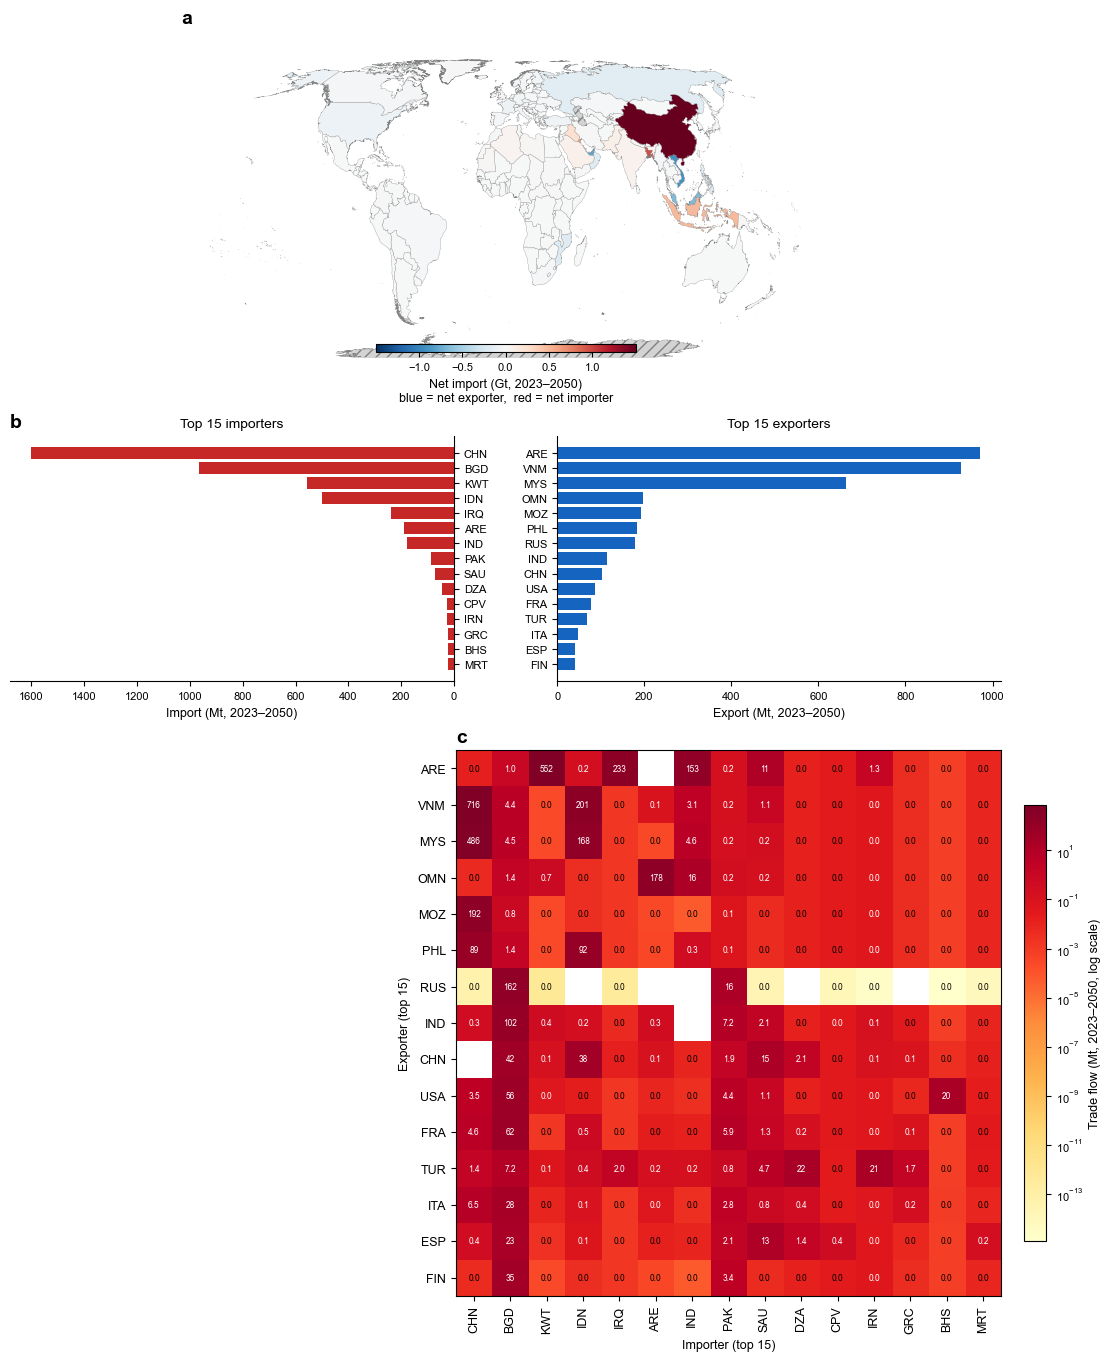

In [5]:
N_BAR = 15      # importers / exporters shown in panel (b)
N_MAT = 15      # matrix dimension: top-N_MAT exporters × top-N_MAT importers

fig = plt.figure(figsize=(11, 13.5), constrained_layout=True)
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 0.9, 2.0])

# ============================ (a) world map ============================
ax_map = fig.add_subplot(gs[0, :])
vmax = float(world['net_import_Gt'].abs().max())
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
world.plot(
    column='net_import_Gt', cmap='RdBu_r', norm=norm,
    edgecolor='0.5', linewidth=0.2,
    missing_kwds={'color': 'lightgrey', 'edgecolor': '0.5', 'linewidth': 0.2, 'hatch': '///'},
    ax=ax_map, zorder=2,
)
ax_map.set_axis_off()
cax = ax_map.inset_axes([0.30, 0.06, 0.40, 0.025])
sm = plt.cm.ScalarMappable(cmap='RdBu_r', norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Net import (Gt, 2023–2050)\nblue = net exporter,  red = net importer', fontsize=9)
cb.ax.tick_params(labelsize=8)
ax_map.set_title('a', loc='left', fontweight='bold', fontsize=14)

# ============================ (b1) top importers ============================
ax_imp = fig.add_subplot(gs[1, 0])
imp_top = trade_df.nlargest(N_BAR, 'import')[['name', 'import']].iloc[::-1]
ax_imp.barh(imp_top.index, imp_top['import'], color='#c62828', edgecolor='none')
ax_imp.set_xlabel('Import (Mt, 2023–2050)', fontsize=9)
ax_imp.tick_params(labelsize=8)
ax_imp.invert_xaxis()
ax_imp.yaxis.tick_right()
ax_imp.spines[['top', 'left']].set_visible(False)
ax_imp.set_title('b', loc='left', fontweight='bold', fontsize=14)
ax_imp.set_title(f'Top {N_BAR} importers', loc='center', fontsize=10)

# ============================ (b2) top exporters ============================
ax_exp = fig.add_subplot(gs[1, 1])
exp_top = trade_df.nlargest(N_BAR, 'export')[['name', 'export']].iloc[::-1]
ax_exp.barh(exp_top.index, exp_top['export'], color='#1565c0', edgecolor='none')
ax_exp.set_xlabel('Export (Mt, 2023–2050)', fontsize=9)
ax_exp.tick_params(labelsize=8)
ax_exp.spines[['top', 'right']].set_visible(False)
ax_exp.set_title(f'Top {N_BAR} exporters', loc='center', fontsize=10)

# ============================ (c) top-exporter × top-importer matrix ============================
# Rows = top-N_MAT exporters (by total export), Cols = top-N_MAT importers (by total import).
row_iso = trade_df.nlargest(N_MAT, 'export').index.tolist()
col_iso = trade_df.nlargest(N_MAT, 'import').index.tolist()
T_sub = T_df.loc[row_iso, col_iso]

M = T_sub.values.astype(float)
M = np.where(M > 0, M, np.nan)

ax_mat = fig.add_subplot(gs[2, :])
norm_mat = LogNorm(vmin=np.nanmin(M), vmax=np.nanmax(M))
im = ax_mat.imshow(M, aspect='equal', cmap='YlOrRd', norm=norm_mat)

# Full labels for every row/col (only N_MAT entries each, so they all fit).
ax_mat.set_xticks(range(N_MAT))
ax_mat.set_xticklabels(col_iso, rotation=90, fontsize=9)
ax_mat.set_yticks(range(N_MAT))
ax_mat.set_yticklabels(row_iso, fontsize=9)
ax_mat.set_xlabel(f'Importer (top {N_MAT})', fontsize=9)
ax_mat.set_ylabel(f'Exporter (top {N_MAT})', fontsize=9)

# Annotate cells with values (Mt) for readability — only label non-NaN cells.
for i in range(N_MAT):
    for j in range(N_MAT):
        v = M[i, j]
        if np.isfinite(v) and v > 0:
            ax_mat.text(j, i, f'{v:.0f}' if v >= 10 else f'{v:.1f}',
                        ha='center', va='center', fontsize=6,
                        color='white' if v > np.nanmedian(M) else 'black')

cb2 = fig.colorbar(im, ax=ax_mat, fraction=0.04, pad=0.02, shrink=0.8)
cb2.set_label('Trade flow (Mt, 2023–2050, log scale)', fontsize=9)
cb2.ax.tick_params(labelsize=8)
ax_mat.set_title('c', loc='left', fontweight='bold', fontsize=14)

out = FIGURES / f'Supplementary-Figure-21.jpg'
fig.savefig(out, dpi=600, bbox_inches='tight')
print(f'Saved: {out}  |  matrix: top {N_MAT} exporters × top {N_MAT} importers')
plt.show()

## Suggested caption

> **Supplementary Figure X. Modelled international aggregate trade flows (BAU scenario, central demand × central reserve, max_r = 3, max_r_surplus = 10).**
> **(a)** Net trade balance per country over 2023–2050 (Gt); red = net importer, blue = net exporter; grey hatched = countries absent from the trade module. **(b)** Top 15 importers (left) and top 15 exporters (right) by traded volume. **(c)** Bilateral trade flow matrix (top 15 exporters × top 15 importers; cell values in Mt, log colour scale; white = no flow). Trade is settled by a Stone (1962) RAS on the 2018–2022 historical bilateral seed, with a distance-gravity fallback for residual flows. Exportable surplus is restricted to reserve within ~500 km of domestic demand (economically reachable), so remote stranded reserve (e.g. Siberian/Saharan interior) is excluded. Total modelled trade ≈ 7 Gt over 2023–2050.

If reporting the sensitivity sweep, append: "Across reserve scenarios L–M–H the net-importer/exporter geography is stable; only volumes scale."